# 10 — ORPO from scratch

## Learning objectives

- Distinguish probability, odds and log odds.
- Implement stable odds preference plus chosen supervised loss.
- Train a response-masked GRU without a reference model.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** ORPO PDF odds.75/.25 and corrected total; Final_ORPO_Practical.ipynb two environments/inference failure; notes Chapter07; ORPO arXiv2403.07691.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Length-normalized odds

$$
\bar\ell_y=\frac{\sum_t m_t\log\pi_\theta(y_t\mid x,y_{<t})}{\sum_t m_t},\quad p_y=e^{\bar\ell_y},\quad o_y=\frac{p_y}{1-p_y}.
$$
$\bar\ell$ mean completion token logp, $m$ mask, $p$ geometric-mean token likelihood score and $o$ odds. These scores do not normalize over all response candidates. Empty completions are invalid.

$$
\Delta_{OR}=\log o_w-\log o_l,\qquad \mathcal L=\mathcal L_{SFT}+\lambda_{OR}[-\log\sigma(\Delta_{OR})].
$$
$w/l$ chosen/rejected; $\lambda_{OR}=.1$ balances imitation and preference. This code averages chosen NLL equally across sequences; TRL's token-averaged SFT can weight variable-length batches differently. TRL calls the coefficient beta, unlike DPO beta or GRPO KL weight. No reference, RM or critic is required.

For toy $p_w=.75,p_l=.25$, odds3 and1/3, ratio9, preference loss.105361, SFT.287682, total.298218. Stable `log(1-exp(logp))` is evaluated with branch indexing and FP32, avoiding inactive singular-branch gradient contamination.

In [2]:
def read_preferences():
    path = ROOT.parent/'reward_preferences_dataset.jsonl'
    if path.exists():
        raw = path.read_bytes(); origin = str(path)
    else:
        # Originals are currently missing from the working tree. Read their Git blob;
        # never restore, overwrite or silently substitute invented preference records.
        gitroot = Path(subprocess.check_output(['git','rev-parse','--show-toplevel'], cwd=ROOT, text=True).strip())
        rel = (ROOT.parent/'reward_preferences_dataset.jsonl').relative_to(gitroot).as_posix()
        raw = subprocess.check_output(['git','show','HEAD:'+rel], cwd=gitroot)
        origin = 'HEAD:'+rel
    expected = json.loads((ROOT/'source_inspection.json').read_text())
    digest = next(r['sha256'] for r in expected if r['source']=='reward_preferences_dataset.jsonl')
    assert hashlib.sha256(raw).hexdigest() == digest, 'Dataset changed: re-audit before proceeding'
    rows = [json.loads(line) for line in raw.decode('utf-8').splitlines()]
    for row in rows:
        assert set(row)=={'prompt','chosen','rejected'}
        assert all(isinstance(row[k],str) and row[k].strip() for k in row)
        assert row['chosen'].strip()!=row['rejected'].strip()
    assert len({r['prompt'].strip().lower() for r in rows})==len(rows)
    print('Dataset origin:',origin,'records:',len(rows),'fields:',list(rows[0]))
    return rows
rows = read_preferences()
indices = np.random.default_rng(42).permutation(len(rows))
train_rows = [rows[i] for i in indices[:14]]
valid_rows = [rows[i] for i in indices[14:17]]
test_rows = [rows[i] for i in indices[17:]]
assert not ({r['prompt'] for r in train_rows} & {r['prompt'] for r in valid_rows+test_rows})
print('Prompt-separated split:',len(train_rows),len(valid_rows),len(test_rows))

Dataset origin: HEAD:13_rlhf_ppo_dpo_orpo/reward_preferences_dataset.jsonl records: 20 fields: ['prompt', 'chosen', 'rejected']
Prompt-separated split: 14 3 3


In [3]:
# Character vocabulary: finite encoding avoids tokenizer downloads and boundary merges.
# This is an educational tokenizer, not a pretrained chat model's tokenizer.
CHARS = sorted(set(''.join(r[k] for r in rows for k in ('prompt','chosen','rejected'))+'Question: Answer:\n'))
vocab = {'<pad>':0,'<bos>':1,'<eos>':2,'<unk>':3, **{c:i+4 for i,c in enumerate(CHARS)}}
def encode(text): return [vocab.get(c,3) for c in text]
def pair_batch(examples, side):
    seqs=[]; response=[]
    for r in examples:
        prefix=[1]+encode('Question: '+r['prompt']+'\nAnswer: ')
        answer=encode(r[side])+[2]
        seqs.append(prefix+answer);response.append([0]*len(prefix)+[1]*len(answer))
    length=max(map(len,seqs))
    ids=torch.tensor([s+[0]*(length-len(s)) for s in seqs])
    attention=ids.ne(0)
    completion=torch.tensor([m+[0]*(length-len(m)) for m in response],dtype=torch.bool)
    return ids,attention,completion

def completion_logps(logits,ids,attention,completion,average=False):
    assert logits.shape[:2]==ids.shape==attention.shape==completion.shape
    target=ids[:,1:]
    assert (target>=0).all() and (target<logits.shape[-1]).all()
    active=completion[:,1:].bool() & attention[:,1:].bool() & attention[:,:-1].bool()
    counts=active.sum(-1)
    if (counts==0).any(): raise ValueError('Empty scored completion')
    selected=F.log_softmax(logits[:,:-1].float(),-1).gather(-1,target.unsqueeze(-1)).squeeze(-1)
    total=selected.masked_fill(~active,0).sum(-1)
    return total/counts if average else total

class TinyLM(nn.Module):
    def __init__(self):
        super().__init__();self.embedding=nn.Embedding(len(vocab),24,padding_idx=0)
        self.rnn=nn.GRU(24,32,batch_first=True);self.head=nn.Linear(32,len(vocab))
    def forward(self,ids): return self.head(self.rnn(self.embedding(ids))[0])

def score(model,batch,average=False):
    ids,att,mask=batch
    return completion_logps(model(ids),ids,att,mask,average)

def finite_step(loss,model,optimizer):
    assert torch.isfinite(loss).all()
    optimizer.zero_grad();loss.backward()
    grads=[p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(torch.isfinite(g).all() for g in grads)
    assert any(g.abs().sum()>0 for g in grads), 'No gradient signal'
    nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()

# Meaningful causal-shift, prompt exclusion, padding and gradient tests.
ids=torch.tensor([[1,4,5,2,0]]); att=ids.ne(0);mask=torch.tensor([[0,0,1,1,0]],dtype=torch.bool)
logits=torch.zeros(1,5,len(vocab),requires_grad=True)
s=completion_logps(logits,ids,att,mask)
assert torch.allclose(s,torch.tensor([-2*math.log(len(vocab))]))
(-s.sum()).backward()
assert logits.grad[0,0].abs().sum()==0   # predicts masked prompt token
assert logits.grad[0,1:3].abs().sum()>0  # predicts response and EOS
assert logits.grad[0,3:].abs().sum()==0  # padding / unused last logits
assert torch.allclose(completion_logps(logits.detach(),ids,att,mask,True),s.detach()/2)
try:
    completion_logps(logits.detach(),ids,att,torch.zeros_like(mask))
    raise AssertionError('Should reject empty completions')
except ValueError: pass
print('Causal shifting, response/padding masking and gradient checks passed.')

Causal shifting, response/padding masking and gradient checks passed.


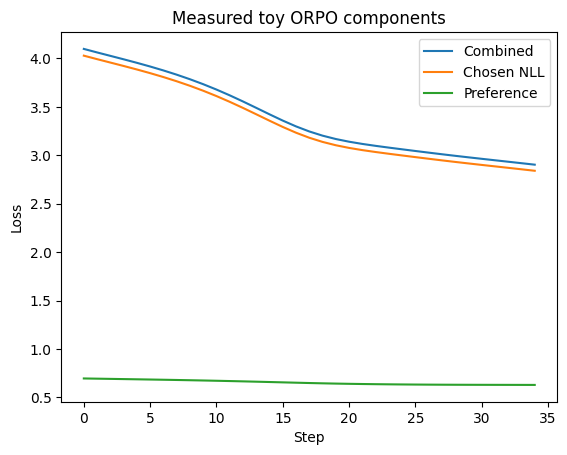

ORPO toy arithmetic: 0.29821813106536865 Training first/final: 4.0983734130859375 2.903223991394043


In [4]:
def log1mexp(logp):
    x=logp.float()
    if (x>=0).any():raise ValueError('Need strictly negative log likelihood')
    result=torch.empty_like(x);far=x < -math.log(2)
    result[far]=torch.log1p(-torch.exp(x[far]))
    result[~far]=torch.log(-torch.expm1(x[~far]))
    return result

def orpo_loss(w,l,coefficient=.1):
    # w/l are completion-MEAN logps. This averages NLL equally across sequences.
    margin=(w-log1mexp(w))-(l-log1mexp(l))
    sft=-w.mean();preference=F.softplus(-margin).mean()
    return sft+coefficient*preference,sft,preference
w=torch.tensor([math.log(.75)],requires_grad=True);l=torch.tensor([math.log(.25)],requires_grad=True)
toy=orpo_loss(w,l)[0];assert abs(toy.item()-.298218124)<1e-6
toy.backward();assert torch.isfinite(w.grad).all() and torch.isfinite(l.grad).all()
edge=torch.tensor([-1e-6,-.1,-1.,-30.],requires_grad=True)
log1mexp(edge).sum().backward();assert torch.isfinite(edge.grad).all()
policy=TinyLM();opt=torch.optim.Adam(policy.parameters(),lr=.003)
chosen=pair_batch(train_rows,'chosen');rejected=pair_batch(train_rows,'rejected')
history=[];parts=[]
for step in range(35):
    loss,sft,pref=orpo_loss(score(policy,chosen,True),score(policy,rejected,True))
    finite_step(loss,policy,opt);history.append(loss.item());parts.append((sft.item(),pref.item()))
plt.plot(history,label='Combined');plt.plot(np.array(parts)[:,0],label='Chosen NLL');plt.plot(np.array(parts)[:,1],label='Preference');plt.legend();plt.xlabel('Step');plt.ylabel('Loss');plt.title('Measured toy ORPO components');plt.show()
print('ORPO toy arithmetic:',toy.item(),'Training first/final:',history[0],history[-1])

In [5]:
print('Validation uses normalized chosen/rejected score differences:')
with torch.no_grad():
    w=score(policy,pair_batch(valid_rows,'chosen'),True);l=score(policy,pair_batch(valid_rows,'rejected'),True)
    print('Validation mean-logp ranking accuracy:',w.gt(l).float().mean().item())

Validation uses normalized chosen/rejected score differences:
Validation mean-logp ranking accuracy: 0.6666666865348816


## Exercises

1. Sweep the preference coefficient and log both components.
2. Use sum logps in a copy and diagnose length effects.
3. Compare equal-sequence and equal-token SFT weighting.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.